In [17]:
# =========================
# Standard library imports
# =========================
import os
import sys
import subprocess
import shutil
import tarfile
import zipfile
import pickle
import random
from pathlib import Path
from datetime import datetime
from io import BytesIO
import urllib.request
from tqdm.auto import tqdm
import time

# =========================
# Third-party libraries
# =========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pycocotools.coco import COCO
import albumentations as A

# =========================
# Cloud / data access
# =========================
import boto3
import kagglehub

random.seed(42)

In [18]:
# Pull default bucket from store
%store -r bucket
bucket = bucket
print(bucket)

s3 = boto3.client("s3")

sagemaker-us-east-1-298748835671


# Downloading Raw Cat Images and Annotations from Kagglehub

In [19]:
temp_dir = "data/temp_cats"
path = kagglehub.dataset_download(handle="crawford/cat-dataset", 
                                  output_dir=temp_dir, 
                                  force_download=True)

100%|██████████| 4.04G/4.04G [00:20<00:00, 216MB/s] 

Extracting files...


In [20]:
# move cats images folder to raw
shutil.move(f"{temp_dir}/cats", "data/raw/cats", copy_function=shutil.copy2)

'data/raw/cats'

In [21]:
# delete unneeded files from kaggle download
try:
    shutil.rmtree(temp_dir)
    print(f"Directory '{temp_dir}' and all its contents deleted.")
except FileNotFoundError:
    print("Error: Directory not found.")
except Exception as e:
    print(f"Error deleting directory: {e}")

Directory 'data/temp_cats' and all its contents deleted.


# Parsing Annotation Files

In [22]:
raw_dir_prefix = "data/raw"
raw_dir = Path(f"{raw_dir_prefix}/cats")
processed_dir = Path("data/processed/cats")
processed_dir.mkdir(parents=True, exist_ok=True)
remote_path_prefix = f"s3://{bucket}/cat-landmarks-project"

rows = []

for img_path in raw_dir.rglob("*.jpg"):
    # Example: annotation file might be "<image>.cat" or similar naming
    ann_path = img_path.with_suffix(img_path.suffix + ".cat")

    if not ann_path.exists():
        continue

    # Read and parse annotation file
    text = ann_path.read_text().strip().split()
    pts = np.array(list(map(float, text[1:])))
    x_idxs = [0, 2, 4, 6, 8, 10, 12, 14, 16]
    y_idxs = [x + 1 for x in x_idxs]
    coord_pairs = [[int(x), int(y)] for x, y in zip(pts[x_idxs], pts[y_idxs])]
    
    remote_path = f"{remote_path_prefix}/{img_path}"

    rows.append({"remote_path":str(remote_path), "local_path": str(img_path), "points": coord_pairs})

cats_ann = pd.DataFrame(rows)

# Expand pts into columns
landmark_features = [     
              "left_eye", 
              "right_eye", 
              "mouth",   
              "left_ear_1", 
              "left_ear_2", 
              "left_ear_3", 
              "right_ear_1", 
              "right_ear_2", 
              "right_ear_3", 
              ]

cats_ann[landmark_features] = pd.DataFrame(cats_ann["points"].to_list())
cats_ann = cats_ann.drop(columns=["points"])
cats_ann.head()

,remote_path,local_path,left_eye,right_eye,mouth,left_ear_1,left_ear_2,left_ear_3,right_ear_1,right_ear_2,right_ear_3
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_000.jpg,"[175, 160]","[239, 162]","[199, 199]","[149, 121]","[137, 78]","[166, 93]","[281, 101]","[312, 96]","[296, 133]"
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_005.jpg,"[96, 96]","[153, 127]","[103, 146]","[48, 20]","[78, -37]","[127, 5]","[210, 52]","[260, 63]","[229, 121]"
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_008.jpg,"[318, 222]","[340, 224]","[327, 238]","[301, 199]","[304, 182]","[321, 196]","[341, 197]","[359, 183]","[361, 203]"
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_011.jpg,"[167, 173]","[242, 185]","[191, 247]","[112, 105]","[118, 0]","[171, 74]","[270, 90]","[353, 35]","[332, 147]"
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_012.jpg,"[115, 122]","[179, 121]","[133, 169]","[95, 70]","[93, 17]","[131, 46]","[233, 39]","[281, 9]","[224, 69]"


# Data Splitting

In [23]:
cats_ann["version"] = cats_ann["local_path"].apply(lambda _: "raw")
n = cats_ann.shape[0]

np.random.seed(42)
n_train = int(0.4 * n)
n_test = int(0.1 * n)
n_val = int(0.1 * n)
n_prod = n - n_train - n_test - n_val

splits = (
    ["train"] * n_train +
    ["test"] * n_test +
    ["validation"] * n_val +
    ["production"] * n_prod
)

np.random.shuffle(splits)
cats_ann["split"] = splits
cats_ann["split"].value_counts()

split
production    4001
train         3998
test           999
validation     999
Name: count, dtype: int64

# Image Augmentation

In [24]:
def augmentation_pipeline(
    src_df: pd.DataFrame,
    local_path_key: str,
    remote_path_key: str,
    coord_cols: list[str],
    metadata_headers: list[str],
    suffix: str,
    split: str,
    composition: A.Compose,
    keypoint_permutation: list[int] | None = None,
) -> pd.DataFrame:

    image_srcs = src_df[local_path_key].values
    output_rows = []

    for img in tqdm(image_srcs, desc="Augmenting images", unit="img"):
        try:
            raw_image = Image.open(img)

            row = (
                src_df.loc[src_df[local_path_key] == img, coord_cols]
                .iloc[0]
            )

            keypoints = np.stack(row.to_list()).astype(np.float32)

            augmentation = composition(
                image=np.asarray(raw_image, dtype=np.uint8),
                keypoints=keypoints,
            )
            
            aug_name = f"{img.split(".")[0]}_{suffix}.jpg"
            aug_keypoints = augmentation["keypoints"].astype(np.int32).tolist()
            if keypoint_permutation is not None:
                aug_keypoints = [aug_keypoints[i] for i in keypoint_permutation]
            aug_image_jpg = Image.fromarray(
                augmentation["image"]
            ).convert("RGB")
            
            remote_path = src_df[remote_path_key][src_df[local_path_key] == img].values[0]
            aug_remote_path = f"{remote_path.split(".")[0]}_{suffix}.jpg"

            aug_row = {
                **dict(zip(coord_cols, aug_keypoints)),
                "remote_path": aug_remote_path,
                "local_path": aug_name,
                "version": suffix,
                "split": split,
            }

            output_rows.append(aug_row)
            aug_image_jpg.save(aug_name)

        except Exception as e:
            tqdm.write(f"[ERROR] {img}: {e}")

    output_df = pd.DataFrame(output_rows, columns=metadata_headers)
    return output_df


In [47]:
# A horizontal flip mirrors the face, so left/right landmark names must be swapped
# to keep each name on the same anatomical point. Ear points are annotated in a
# consistent rotational order (ear_1 -> ear_2 -> ear_3), which a mirror reverses.
mirror_landmark_map = {
    "left_eye": "right_eye", "right_eye": "left_eye", "mouth": "mouth",
    "left_ear_1": "right_ear_3", "left_ear_2": "right_ear_2", "left_ear_3": "right_ear_1",
    "right_ear_1": "left_ear_3", "right_ear_2": "left_ear_2", "right_ear_3": "left_ear_1",
}
mirror_permutation = [landmark_features.index(mirror_landmark_map[name]) for name in landmark_features]

# Version 2 Image Augmentations
cat_aug_v2 = A.Compose(
    [
        A.HorizontalFlip(p=1),
        A.GaussNoise(p=1, noise_scale_factor=.005),
    ],
    keypoint_params=A.KeypointParams(format="xy", remove_invisible=False)
)

# Version 3 Image Augmentations
# Horizontal + vertical flip is a 180° rotation, which preserves left/right
# identity, so no relabeling is needed
cat_aug_v3 = A.Compose(
    [
        A.HorizontalFlip(p=1),
		A.VerticalFlip(p=1),
        A.Blur(p=1, blur_limit=(3, 5)),
    ],
    keypoint_params=A.KeypointParams(format="xy", remove_invisible=False)
)

# Only augmenting Training data
aug_df = cats_ann[(cats_ann["split"]=="train") & (cats_ann["version"]=="raw")]
print(aug_df.shape)

(3998, 13)


In [48]:
aug_meta_v2 = augmentation_pipeline(aug_df, 
                      local_path_key="local_path", 
                      remote_path_key="remote_path",
                      coord_cols=landmark_features,
                      metadata_headers=cats_ann.columns, 
                      split="train",
                      suffix="v2", 
                      composition=cat_aug_v2,
                      keypoint_permutation=mirror_permutation)

Augmenting images:   0%|          | 0/3998 [00:00<?, ?img/s]

In [49]:
aug_meta_v2.head()

,remote_path,local_path,left_eye,right_eye,mouth,left_ear_1,left_ear_2,left_ear_3,right_ear_1,right_ear_2,right_ear_3,version,split
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_008_v2.jpg,"[181, 222]","[159, 224]","[172, 238]","[198, 199]","[195, 182]","[178, 196]","[158, 197]","[140, 183]","[138, 203]",v2,train
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_017_v2.jpg,"[613, 464]","[512, 344]","[455, 494]","[801, 473]","[910, 370]","[735, 359]","[643, 250]","[686, 75]","[547, 200]",v2,train
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_027_v2.jpg,"[270, 142]","[226, 147]","[252, 171]","[289, 109]","[302, 85]","[269, 98]","[208, 103]","[172, 80]","[198, 116]",v2,train
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_029_v2.jpg,"[122, 113]","[57, 112]","[88, 165]","[156, 70]","[172, 5]","[121, 40]","[64, 40]","[30, 7]","[26, 70]",v2,train
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000003_007_v2.jpg,"[170, 116]","[99, 116]","[126, 180]","[222, 72]","[221, 0]","[173, 34]","[108, 35]","[50, 3]","[71, 76]",v2,train


In [50]:
aug_meta_v3 = augmentation_pipeline(aug_df, 
                      local_path_key="local_path", 
                      remote_path_key="remote_path",
                      coord_cols=landmark_features,
                      metadata_headers=cats_ann.columns, 
                      split="train",
                      suffix="v3", 
                      composition=cat_aug_v3)

Augmenting images:   0%|          | 0/3998 [00:00<?, ?img/s]

In [51]:
# Combining metadata
cats_ann_combined = pd.concat([cats_ann, aug_meta_v2, aug_meta_v3])

print(cats_ann.shape)
print(cats_ann_combined.shape)

cats_ann_combined.head()

(9997, 13)
(17993, 13)


,remote_path,local_path,left_eye,right_eye,mouth,left_ear_1,left_ear_2,left_ear_3,right_ear_1,right_ear_2,right_ear_3,version,split
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_000.jpg,"[175, 160]","[239, 162]","[199, 199]","[149, 121]","[137, 78]","[166, 93]","[281, 101]","[312, 96]","[296, 133]",raw,test
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_005.jpg,"[96, 96]","[153, 127]","[103, 146]","[48, 20]","[78, -37]","[127, 5]","[210, 52]","[260, 63]","[229, 121]",raw,test
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_008.jpg,"[318, 222]","[340, 224]","[327, 238]","[301, 199]","[304, 182]","[321, 196]","[341, 197]","[359, 183]","[361, 203]",raw,train
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_011.jpg,"[167, 173]","[242, 185]","[191, 247]","[112, 105]","[118, 0]","[171, 74]","[270, 90]","[353, 35]","[332, 147]",raw,test
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_012.jpg,"[115, 122]","[179, 121]","[133, 169]","[95, 70]","[93, 17]","[131, 46]","[233, 39]","[281, 9]","[224, 69]",raw,production


In [52]:
cats_ann_combined["split"].value_counts()

split
train         11994
production     4001
test            999
validation      999
Name: count, dtype: int64

In [53]:
# Expanding coordinates into individual feature columns for modeling
def get_x_coord(coord_pair: object):
    return coord_pair[0]

def get_y_coord(coord_pair: object):
    return coord_pair[1]

for feature in landmark_features:
    x_feat_name = feature + "_x"
    y_feat_name = feature + "_y"
    
    cats_ann_combined[x_feat_name] = cats_ann_combined[feature].apply(get_x_coord)
    cats_ann_combined[y_feat_name] = cats_ann_combined[feature].apply(get_y_coord)

cats_ann_combined.head()

,remote_path,local_path,left_eye,right_eye,mouth,left_ear_1,left_ear_2,left_ear_3,right_ear_1,right_ear_2,...,left_ear_2_x,left_ear_2_y,left_ear_3_x,left_ear_3_y,right_ear_1_x,right_ear_1_y,right_ear_2_x,right_ear_2_y,right_ear_3_x,right_ear_3_y
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_000.jpg,"[175, 160]","[239, 162]","[199, 199]","[149, 121]","[137, 78]","[166, 93]","[281, 101]","[312, 96]",...,137,78,166,93,281,101,312,96,296,133
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_005.jpg,"[96, 96]","[153, 127]","[103, 146]","[48, 20]","[78, -37]","[127, 5]","[210, 52]","[260, 63]",...,78,-37,127,5,210,52,260,63,229,121
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_008.jpg,"[318, 222]","[340, 224]","[327, 238]","[301, 199]","[304, 182]","[321, 196]","[341, 197]","[359, 183]",...,304,182,321,196,341,197,359,183,361,203
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_011.jpg,"[167, 173]","[242, 185]","[191, 247]","[112, 105]","[118, 0]","[171, 74]","[270, 90]","[353, 35]",...,118,0,171,74,270,90,353,35,332,147
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_012.jpg,"[115, 122]","[179, 121]","[133, 169]","[95, 70]","[93, 17]","[131, 46]","[233, 39]","[281, 9]",...,93,17,131,46,233,39,281,9,224,69


# Checking Image Variants

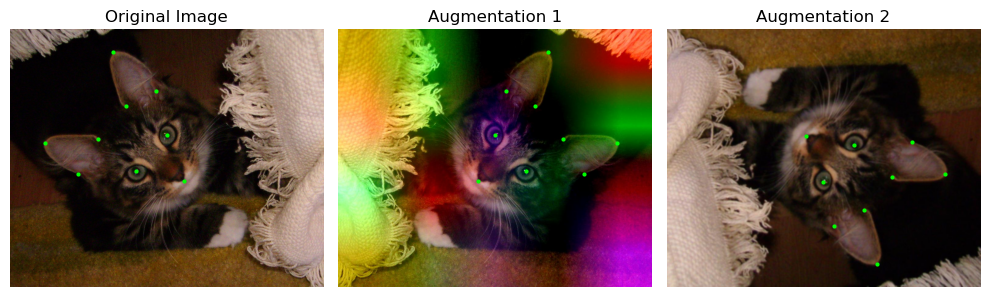

In [54]:
TEST_FILE_PREFIX = Path("data/raw/cats")

IMAGE_REFS = [
    "CAT_00/00000001_017.jpg",
    "CAT_00/00000001_017_v2.jpg",
    "CAT_00/00000001_017_v3.jpg",
]

TITLES = [
    "Original Image",
    "Augmentation 1",
    "Augmentation 2",
]

def load_image_and_keypoints(image_path: Path, ann_df: pd.DataFrame):
    image = Image.open(image_path)

    keypoints = (
        ann_df[landmark_features]
        .loc[ann_df["local_path"] == str(image_path)]
        .iloc[0]
        .values
    )

    x_vals = [pt[0] for pt in keypoints]
    y_vals = [pt[1] for pt in keypoints]

    return image, x_vals, y_vals


image_paths = [TEST_FILE_PREFIX / ref for ref in IMAGE_REFS]

fig, axes = plt.subplots(1, len(image_paths), figsize=(10, 4))

for ax, image_path, title in zip(axes, image_paths, TITLES):
    image, x_vals, y_vals = load_image_and_keypoints(image_path, cats_ann_combined)

    ax.imshow(image)
    ax.scatter(x_vals, y_vals, s=4, c="lime")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Downloading Background Images

In [58]:
# Setting up noncats directory
noncats_dir = Path("data/raw/noncats")
if not noncats_dir.exists():
    os.mkdir(noncats_dir)

ann_dir = noncats_dir / "annotations"
ann_zip_path = noncats_dir / "annotations_trainval2017.zip"

ann_zip_path

PosixPath('data/raw/noncats/annotations_trainval2017.zip')

In [26]:
# Download Annotations
coco_ann_zip_url = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"

urllib.request.urlretrieve(coco_ann_zip_url, ann_zip_path)

if noncats_dir.exists():
    with zipfile.ZipFile(ann_zip_path, "r") as z:
        z.extractall(noncats_dir)

# Load annotations
instances_json = ann_dir / "instances_train2017.json"
coco = COCO(str(instances_json))

# Get category id for "cat" images
cat_id = coco.getCatIds(catNms=["cat"])[0]

# Image IDs that contain at least one cat
cat_img_ids = set(coco.getImgIds(catIds=[cat_id]))

# All training image IDs
all_img_ids = set(coco.getImgIds())

# Non-cat image IDs
noncat_img_ids = list(all_img_ids - cat_img_ids)

loading annotations into memory...
Done (t=10.09s)
creating index...
index created!


In [27]:
NUM_IMAGES = 15_000
MAX_RESTARTS = 5
SLEEP_BETWEEN_RESTARTS = 5
BASE_URL = "http://images.cocodataset.org/train2017"

random.seed(42)

out_dir = noncats_dir / "noncat_images"
out_dir.mkdir(parents=True, exist_ok=True)

sample_img_ids = random.sample(noncat_img_ids, k=NUM_IMAGES)
imgs = coco.loadImgs(sample_img_ids)

# Map ID -> image metadata (fast lookup)
img_by_id = {img["id"]: img for img in imgs}

def get_downloaded_img_ids(directory: Path) -> set[int]:
    """Return set of COCO image IDs already downloaded."""
    ids = set()
    for fname in os.listdir(directory):
        stem = Path(fname).stem
        if stem.isdigit():
            ids.add(int(stem.lstrip("0") or "0"))
    return ids


def download_images(images):
    failed = []
    for img in tqdm(images, desc="Downloading Images From COCO...", unit="image"):
        fname = img["file_name"]
        dst = out_dir / fname

        if dst.exists():
            continue  # restart-safe

        url = f"{BASE_URL}/{fname}"
        try:
            urllib.request.urlretrieve(url, dst)
        except Exception as e:
            failed.append(img["id"])
    return failed


restart_count = 0
remaining_ids = set(sample_img_ids)

while remaining_ids and restart_count <= MAX_RESTARTS:
    downloaded_ids = get_downloaded_img_ids(out_dir)
    remaining_ids = remaining_ids - downloaded_ids

    if not remaining_ids:
        break

    remaining_imgs = [img_by_id[i] for i in remaining_ids]

    print(
        f"\nRestart {restart_count + 1}/{MAX_RESTARTS} — "
        f"{len(remaining_imgs)} images remaining"
    )

    failed_ids = download_images(remaining_imgs)

    # Prepare for next pass
    remaining_ids = set(failed_ids)
    restart_count += 1

    if remaining_ids:
        time.sleep(SLEEP_BETWEEN_RESTARTS)

if remaining_ids:
    print(f"\n⚠️ Stopped after {MAX_RESTARTS} restarts.")
    print(f"{len(remaining_ids)} images could not be downloaded.")
else:
    print("\n✅ All images downloaded successfully.")



Restart 1/5 — 15000 images remaining



✅ All images downloaded successfully.


# Building File Manifest

In [55]:
def get_image_metadata(img_path: str) -> tuple[int | None, int | None, int | None]:
    try:
        img = Image.open(Path(img_path))
        width, height = img.size
        file_size = os.stat(img_path).st_size

        return file_size, width, height
    except Exception:
        return None, None, None

In [56]:
cats_ann_combined[["file_size", "width", "height"]] = cats_ann_combined["local_path"].apply(get_image_metadata).to_list()
cats_ann_combined["label"] = cats_ann_combined["local_path"].apply(lambda _: 1)

cats_ann_combined.head()

,remote_path,local_path,left_eye,right_eye,mouth,left_ear_1,left_ear_2,left_ear_3,right_ear_1,right_ear_2,...,right_ear_1_x,right_ear_1_y,right_ear_2_x,right_ear_2_y,right_ear_3_x,right_ear_3_y,file_size,width,height,label
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_000.jpg,"[175, 160]","[239, 162]","[199, 199]","[149, 121]","[137, 78]","[166, 93]","[281, 101]","[312, 96]",...,281,101,312,96,296,133,469801,375,500,1
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_005.jpg,"[96, 96]","[153, 127]","[103, 146]","[48, 20]","[78, -37]","[127, 5]","[210, 52]","[260, 63]",...,210,52,260,63,229,121,469801,500,375,1
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_008.jpg,"[318, 222]","[340, 224]","[327, 238]","[301, 199]","[304, 182]","[321, 196]","[341, 197]","[359, 183]",...,341,197,359,183,361,203,469801,500,375,1
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_011.jpg,"[167, 173]","[242, 185]","[191, 247]","[112, 105]","[118, 0]","[171, 74]","[270, 90]","[353, 35]",...,270,90,353,35,332,147,310372,500,375,1
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_012.jpg,"[115, 122]","[179, 121]","[133, 169]","[95, 70]","[93, 17]","[131, 46]","[233, 39]","[281, 9]",...,233,39,281,9,224,69,310372,500,333,1


In [59]:
# Generating metadata for noncat images
noncats_img_dir = noncats_dir/"noncat_images"
local_noncat_images = os.listdir(noncats_img_dir)

local_paths_noncat_images = [f"{noncats_img_dir}/{img}" for img in local_noncat_images]
remote_paths_noncat_images = [f"{remote_path_prefix}/{path}" for path in local_paths_noncat_images]

noncats_metadata = pd.DataFrame({"remote_path": remote_paths_noncat_images, "local_path": local_paths_noncat_images})
noncats_metadata[["file_size", "width", "height"]] = noncats_metadata["local_path"].apply(get_image_metadata).to_list()
noncats_metadata.head()

,remote_path,local_path,file_size,width,height
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000098304.jpg,111609,640,424
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000425988.jpg,137421,640,498
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000229381.jpg,120545,456,640
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000393225.jpg,174759,640,428
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000032779.jpg,154333,480,640


In [60]:
combined_image_catalogue = pd.concat([noncats_metadata, 
                                     cats_ann_combined[noncats_metadata.columns]], 
                                     ignore_index=True)

def labeler(local_path: str):
    if local_path.startswith(str(noncats_dir)):
        return 0
    else:
        return 1
    
combined_image_catalogue["label"] = combined_image_catalogue["local_path"].apply(labeler)
combined_image_catalogue["ingest_time"] = (combined_image_catalogue["local_path"]
                                         .apply(lambda _: datetime.now().isoformat()))

combined_image_catalogue.head()

,remote_path,local_path,file_size,width,height,label,ingest_time
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000098304.jpg,111609,640,424,0,2026-02-17T18:26:46.318504
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000425988.jpg,137421,640,498,0,2026-02-17T18:26:46.318512
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000229381.jpg,120545,456,640,0,2026-02-17T18:26:46.318514
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000393225.jpg,174759,640,428,0,2026-02-17T18:26:46.318516
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/noncats/noncat_images/000000032779.jpg,154333,480,640,0,2026-02-17T18:26:46.318518


# Upload Metadata to S3

In [61]:
# Save artifacts to disk
cats_ann_combined.to_csv("data/processed/cats/annotations.csv", index=False)
cats_ann_combined.to_parquet("data/processed/cats/annotations.pqt", index=False)

noncats_processed_dir = Path("data/processed/noncats/")
combined_processed_dir = Path("data/processed/combined/")

if not noncats_processed_dir.exists():
    os.mkdir(noncats_processed_dir)
    
if not combined_processed_dir.exists():
    os.mkdir(combined_processed_dir)
    
noncats_metadata.to_csv(noncats_processed_dir / "metadata.csv", index=False)
noncats_metadata.to_parquet(noncats_processed_dir / "metadata.pqt", index=False)

combined_image_catalogue.to_csv(
    combined_processed_dir / "combined_metadata.csv", index=False
)
combined_image_catalogue.to_parquet(
    combined_processed_dir / "combined_metadata.pqt", index=False
)

# Upload the locally generated annotations file to S3
annotations_dest_path = "cat-landmarks-project/data/processed/cats/annotations"
s3.upload_file(
    "data/processed/cats/annotations.pqt",
    bucket,
    f"{annotations_dest_path}/annotations.pqt",
)

# Upload non-cat metadata file to S3
noncats_metadata_dest_path = "cat-landmarks-project/data/processed/noncats/metadata"
s3.upload_file(
    noncats_processed_dir / "metadata.pqt",
    bucket,
    f"{noncats_metadata_dest_path}/metadata.pqt",
)

# Upload combined metadata file to S3
combined_metadata_dest_path = "cat-landmarks-project/data/processed/combined/metadata"
s3.upload_file(
    combined_processed_dir / "combined_metadata.pqt",
    bucket,
    f"{combined_metadata_dest_path}/combined_metadata.pqt",
)

# Upload Images to S3

In [33]:
# Uploading images
for file in tqdm(combined_image_catalogue["local_path"],
                 desc="Uploading images to S3",
                 unit="image"):
    dest = combined_image_catalogue["remote_path"][combined_image_catalogue["local_path"]==file].values[0]
    dest = dest.replace("s3://" + bucket + "/", "")

    try:
        s3.upload_file(
			file,
			bucket,
			dest
		)
    except Exception as e:
        tqdm.write(f"[ERROR] {e} - file: {file}")

Uploading images to S3:   0%|          | 0/40991 [00:00<?, ?image/s]

In [64]:
# Project-level S3 locations
project_prefix = "cat-landmarks-project"
s3_raw_cats_prefix = f"s3://{bucket}/{project_prefix}/data/raw/cats/"
s3_raw_noncats_prefix = f"s3://{bucket}/{project_prefix}/data/raw/noncats/noncat_images/"
s3_processed_combined_prefix = f"s3://{bucket}/{project_prefix}/data/processed/combined/"
s3_processed_cats_prefix = f"s3://{bucket}/{project_prefix}/data/processed/cats/"

ingestion_completed = True

%store project_prefix
%store s3_raw_cats_prefix
%store s3_raw_noncats_prefix
%store s3_processed_combined_prefix
%store s3_processed_cats_prefix
%store ingestion_completed

Stored 'project_prefix' (str)
Stored 's3_raw_cats_prefix' (str)
Stored 's3_raw_noncats_prefix' (str)
Stored 's3_processed_combined_prefix' (str)
Stored 's3_processed_cats_prefix' (str)
Stored 'ingestion_completed' (bool)


In [65]:
%store

Stored variables and their in-db values:
bucket                                     -> 'sagemaker-us-east-1-298748835671'
database_name                              -> 'cat_landmarking'
ingest_create_athena_db_passed             -> True
ingestion_completed                        -> True
landmarks_feature_group_name               -> 'landmarks-feature-group-17-04-03-42'
landmarks_table                            -> 'cat_annotations'
manifest_table                             -> 'image_manifest'
project_prefix                             -> 'cat-landmarks-project'
s3_athena_results_dir                      -> 's3://sagemaker-us-east-1-298748835671/cat-landmar
s3_processed_cats_prefix                   -> 's3://sagemaker-us-east-1-298748835671/cat-landmar
s3_processed_combined_prefix               -> 's3://sagemaker-us-east-1-298748835671/cat-landmar
s3_raw_cats_prefix                         -> 's3://sagemaker-us-east-1-298748835671/cat-landmar
s3_raw_noncats_prefix                      